<a href="https://colab.research.google.com/github/siyaagarwal2005/sepsis-prediction-using-LSTM/blob/main/5_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook V — Evaluation

---

**Project:** AI-Based Sepsis Early Warning System  
**Dataset:** PhysioNet Challenge 2019  
**Author:** *Siya Agarwal*  
**Date:** *06 March, 2026*

---

### Purpose
Comprehensively evaluate the trained LSTM model on the held-out test set.
This notebook answers the core clinical question:
> *How well does the model identify sepsis patients before clinical onset,
> and what is the tradeoff between catching every case and avoiding false alarms?*

### Evaluation Framework
| Metric | What it measures |
|--------|------------------|
| **AUROC** | Overall ranking ability — primary metric |
| **AUPRC** | Performance under class imbalance — secondary metric |
| **Precision** | Of all sepsis alerts, how many were correct? |
| **Recall (Sensitivity)** | Of all actual sepsis cases, how many were caught? |
| **F1-Score** | Harmonic mean of precision and recall |
| **Confusion Matrix** | Full breakdown of TP, TN, FP, FN at threshold=0.5 |

### Inputs
- `processed_data/y_test.npy` — true labels
- `processed_data/y_pred_proba.npy` — model probability outputs

### Outputs
- `results/roc_curve.png`
- `results/pr_curve.png`
- `results/confusion_matrix.png`
- `results/threshold_analysis.png`
- `results/evaluation_summary.csv`

---
## Section 0 — Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.metrics import (
    roc_curve, auc,
    precision_recall_curve, average_precision_score,
    confusion_matrix, classification_report,
    f1_score, precision_score, recall_score, roc_auc_score
)
from IPython.display import display

# ── Project paths ──────────────────────────────────────────────────────────────
BASE_PATH      = '/content/drive/MyDrive/sepsis_project/'
PROCESSED_PATH = BASE_PATH + 'processed_data/'
RESULTS_PATH   = BASE_PATH + 'results/'

os.makedirs(RESULTS_PATH, exist_ok=True)

sns.set_theme(style='whitegrid', palette='muted')
print('Setup complete.')

Setup complete.


---
## Section 1 — Load Predictions

We load the true test labels and the model's predicted probabilities saved by Notebook IV.
No model reloading needed — we only need the outputs.

In [ ]:
y_test       = np.load(PROCESSED_PATH + 'y_test.npy')
y_pred_proba = np.load(PROCESSED_PATH + 'y_pred_proba.npy')

print('=== Loaded Arrays ===')
print(f'y_test       : {y_test.shape},  dtype={y_test.dtype}')
print(f'y_pred_proba : {y_pred_proba.shape}, dtype={y_pred_proba.dtype}')
print(f'\nTrue sepsis sequences  : {int(y_test.sum()):,} ({y_test.mean()*100:.2f}%)')
print(f'Prediction range       : [{y_pred_proba.min():.4f}, {y_pred_proba.max():.4f}]')
print(f'Mean predicted risk    : {y_pred_proba.mean():.4f}')

=== Loaded Arrays ===
y_test       : (263206,),  dtype=float32
y_pred_proba : (263206,), dtype=float32

True sepsis sequences  : 4,794 (1.82%)
Prediction range       : [0.0142, 0.9342]
Mean predicted risk    : 0.3423


---
## Section 2 — ROC Curve and AUROC

The ROC (Receiver Operating Characteristic) curve plots:
- **X-axis:** False Positive Rate — how often we falsely alarm on non-sepsis patients
- **Y-axis:** True Positive Rate (Recall) — how often we correctly catch sepsis

Each point on the curve corresponds to a different decision threshold.
The **AUROC** (Area Under this Curve) summarises performance across all thresholds:
- AUROC = 1.0 → perfect classifier
- AUROC = 0.5 → random guessing (the diagonal line)
- AUROC > 0.75 → clinically useful for early warning

AUROC is our primary metric because it is threshold-independent and insensitive
to class imbalance.

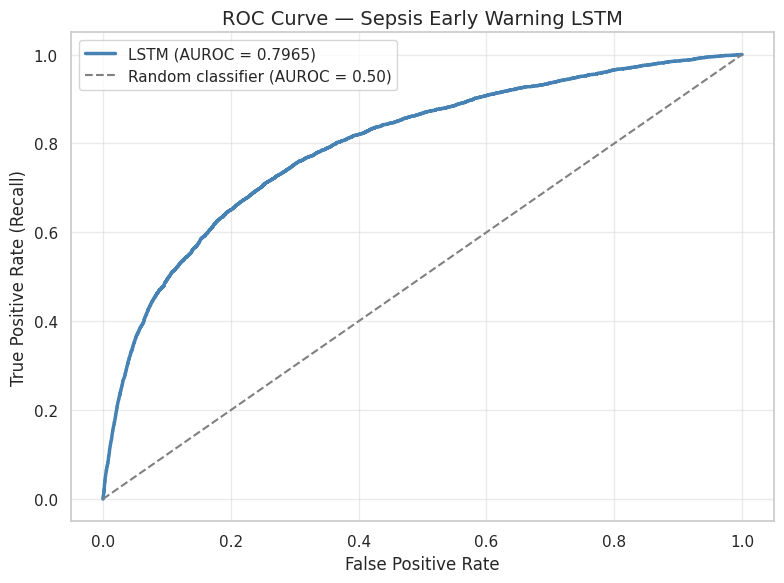

AUROC: 0.7965


In [ ]:
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_proba)
auroc = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(fpr, tpr, color='steelblue', linewidth=2.5,
        label=f'LSTM (AUROC = {auroc:.4f})')
ax.plot([0, 1], [0, 1], color='gray', linestyle='--',
        linewidth=1.5, label='Random classifier (AUROC = 0.50)')

ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate (Recall)', fontsize=12)
ax.set_title('ROC Curve — Sepsis Early Warning LSTM', fontsize=14)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig(RESULTS_PATH + 'roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'AUROC: {auroc:.4f}')

---
## Section 3 — Precision-Recall Curve and AUPRC

The PR curve is the second most important plot for imbalanced classification.

- **Precision:** Of all sequences the model flagged as sepsis, what fraction actually were?
- **Recall:** Of all actual sepsis sequences, what fraction did the model catch?

There is a fundamental tension between these two:
- Lowering the threshold → catches more sepsis (higher recall) but more false alarms (lower precision)
- Raising the threshold → fewer false alarms (higher precision) but misses more cases (lower recall)

The **AUPRC** (Area Under PR Curve) summarises this tradeoff.  
A random classifier on a 7.27% positive rate dataset has AUPRC ≈ 0.073.  
Anything substantially above that is meaningful.

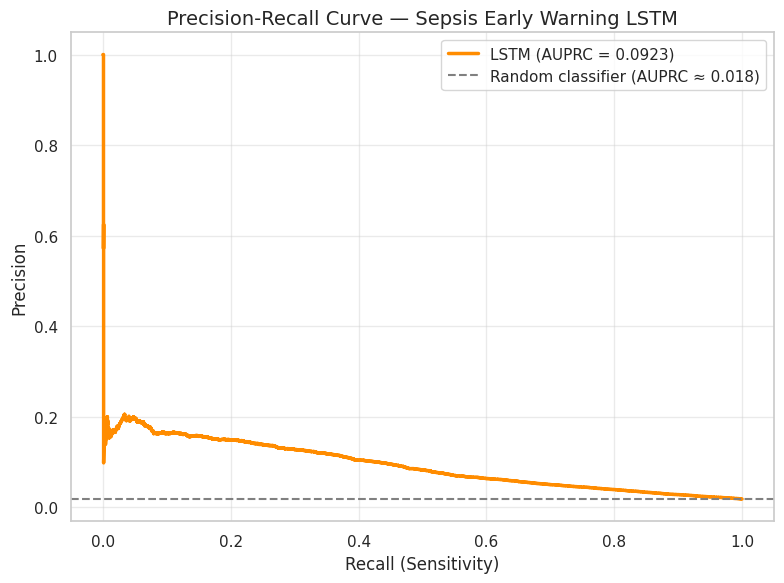

AUPRC    : 0.0923
Baseline : 0.0182  (random classifier on this class distribution)


In [ ]:
precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_proba)
auprc = average_precision_score(y_test, y_pred_proba)
baseline = y_test.mean()   # random classifier baseline

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(recall_vals, precision_vals, color='darkorange', linewidth=2.5,
        label=f'LSTM (AUPRC = {auprc:.4f})')
ax.axhline(y=baseline, color='gray', linestyle='--', linewidth=1.5,
           label=f'Random classifier (AUPRC ≈ {baseline:.3f})')

ax.set_xlabel('Recall (Sensitivity)', fontsize=12)
ax.set_ylabel('Precision', fontsize=12)
ax.set_title('Precision-Recall Curve — Sepsis Early Warning LSTM', fontsize=14)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig(RESULTS_PATH + 'pr_curve.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'AUPRC    : {auprc:.4f}')
print(f'Baseline : {baseline:.4f}  (random classifier on this class distribution)')

---
## Section 4 — Confusion Matrix at Threshold = 0.5

A confusion matrix shows the four possible prediction outcomes at a fixed threshold:

| | Predicted: No Sepsis | Predicted: Sepsis |
|---|---|---|
| **Actual: No Sepsis** | True Negative (TN) ✅ | False Positive (FP) ⚠️ |
| **Actual: Sepsis** | False Negative (FN) ☠️ | True Positive (TP) ✅ |

In a clinical context:
- **False Negatives (FN)** are the most dangerous — missed sepsis cases
- **False Positives (FP)** cause alert fatigue — unnecessary interventions

Threshold = 0.5 is the default starting point. Section 5 explores other thresholds.

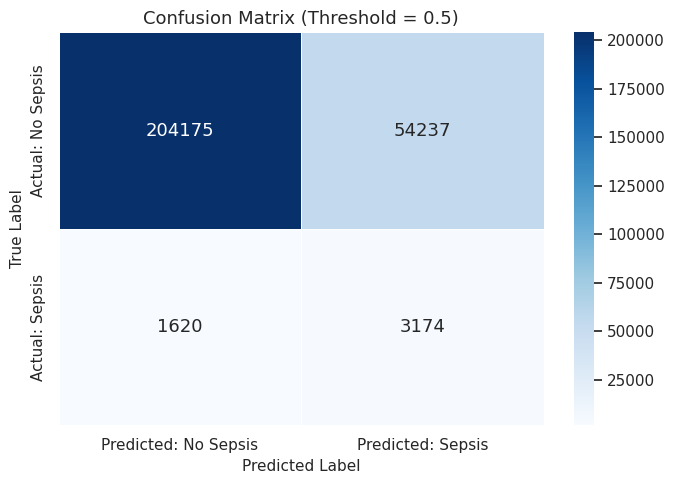

At threshold = 0.5:
  True Positives  (TP) : 3,174  — sepsis cases correctly caught
  True Negatives  (TN) : 204,175  — non-sepsis correctly cleared
  False Positives (FP) : 54,237  — false alarms
  False Negatives (FN) : 1,620  — missed sepsis cases (most critical)


In [ ]:
THRESHOLD = 0.5
y_pred_binary = (y_pred_proba >= THRESHOLD).astype(int)

cm = confusion_matrix(y_test, y_pred_binary)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Predicted: No Sepsis', 'Predicted: Sepsis'],
    yticklabels=['Actual: No Sepsis', 'Actual: Sepsis'],
    ax=ax, linewidths=0.5, annot_kws={'size': 13}
)
ax.set_title(f'Confusion Matrix (Threshold = {THRESHOLD})', fontsize=13)
ax.set_ylabel('True Label', fontsize=11)
ax.set_xlabel('Predicted Label', fontsize=11)

plt.tight_layout()
plt.savefig(RESULTS_PATH + 'confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'At threshold = {THRESHOLD}:')
print(f'  True Positives  (TP) : {tp:,}  — sepsis cases correctly caught')
print(f'  True Negatives  (TN) : {tn:,}  — non-sepsis correctly cleared')
print(f'  False Positives (FP) : {fp:,}  — false alarms')
print(f'  False Negatives (FN) : {fn:,}  — missed sepsis cases (most critical)')

---
## Section 5 — Classification Report

Full precision, recall, and F1-score breakdown at threshold = 0.5.

In [ ]:
report = classification_report(
    y_test, y_pred_binary,
    target_names=['No Sepsis (0)', 'Sepsis (1)'],
    digits=4
)

print('=== Classification Report (Threshold = 0.5) ===')
print(report)

# Individual metrics
prec   = precision_score(y_test, y_pred_binary)
rec    = recall_score(y_test, y_pred_binary)
f1     = f1_score(y_test, y_pred_binary)

print(f'Precision : {prec:.4f}  — of all sepsis alerts, this fraction were real')
print(f'Recall    : {rec:.4f}  — of all real sepsis cases, this fraction were caught')
print(f'F1-Score  : {f1:.4f}  — harmonic mean of precision and recall')
print(f'AUROC     : {auroc:.4f}  — primary metric')

=== Classification Report (Threshold = 0.5) ===
               precision    recall  f1-score   support

No Sepsis (0)     0.9921    0.7901    0.8797    258412
   Sepsis (1)     0.0553    0.6621    0.1020      4794

     accuracy                         0.7878    263206
    macro avg     0.5237    0.7261    0.4909    263206
 weighted avg     0.9751    0.7878    0.8655    263206

Precision : 0.0553  — of all sepsis alerts, this fraction were real
Recall    : 0.6621  — of all real sepsis cases, this fraction were caught
F1-Score  : 0.1020  — harmonic mean of precision and recall
AUROC     : 0.7965  — primary metric


---
## Section 6 — Threshold Sensitivity Analysis

The choice of decision threshold is a **clinical policy decision**, not a statistical one.

- In a resource-constrained ICU, a higher threshold reduces false alarms
  at the cost of missing some sepsis cases.
- In a high-risk ICU where missing sepsis is catastrophic, a lower threshold
  catches almost every case but generates more false alarms.

This plot shows how precision, recall, and F1 change as the threshold varies,
helping identify the clinically optimal operating point.

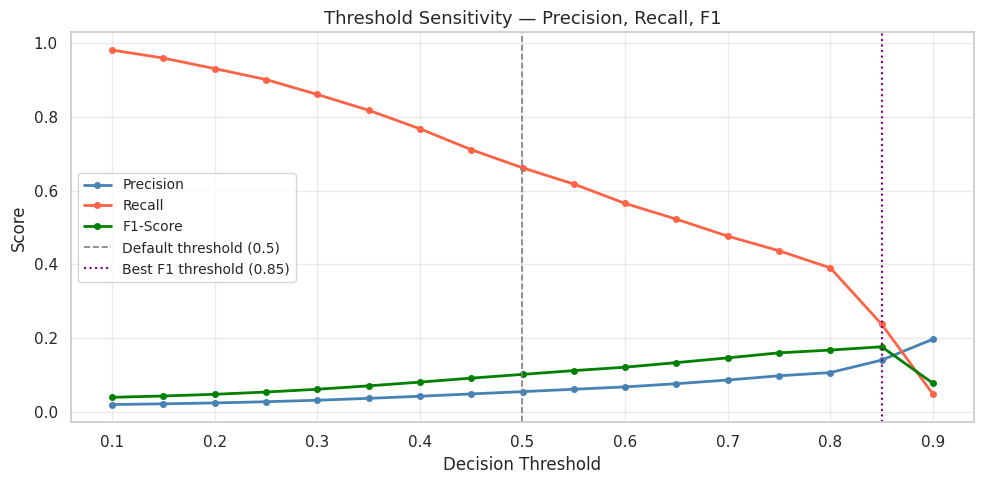

Best F1 score     : 0.1769
At threshold      : 0.85
Precision at best : 0.1407
Recall at best    : 0.2380


In [ ]:
thresholds = np.arange(0.1, 0.91, 0.05)
results = []

for t in thresholds:
    y_pred_t = (y_pred_proba >= t).astype(int)
    if y_pred_t.sum() == 0:   # avoid division by zero if no positives predicted
        results.append({'threshold': t, 'precision': 0, 'recall': 0, 'f1': 0})
        continue
    results.append({
        'threshold': t,
        'precision': precision_score(y_test, y_pred_t, zero_division=0),
        'recall'   : recall_score(y_test, y_pred_t, zero_division=0),
        'f1'       : f1_score(y_test, y_pred_t, zero_division=0)
    })

thresh_df = pd.DataFrame(results)

# ── Plot ───────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(thresh_df['threshold'], thresh_df['precision'],
        label='Precision', linewidth=2, color='steelblue', marker='o', markersize=4)
ax.plot(thresh_df['threshold'], thresh_df['recall'],
        label='Recall',    linewidth=2, color='tomato',    marker='o', markersize=4)
ax.plot(thresh_df['threshold'], thresh_df['f1'],
        label='F1-Score',  linewidth=2, color='green',     marker='o', markersize=4)

ax.axvline(x=0.5, color='gray', linestyle='--', linewidth=1.2, label='Default threshold (0.5)')

# Mark the threshold with best F1
best_f1_row = thresh_df.loc[thresh_df['f1'].idxmax()]
ax.axvline(x=best_f1_row['threshold'], color='purple', linestyle=':',
           linewidth=1.5, label=f'Best F1 threshold ({best_f1_row["threshold"]:.2f})')

ax.set_xlabel('Decision Threshold', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Threshold Sensitivity — Precision, Recall, F1', fontsize=13)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig(RESULTS_PATH + 'threshold_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Best F1 score     : {best_f1_row["f1"]:.4f}')
print(f'At threshold      : {best_f1_row["threshold"]:.2f}')
print(f'Precision at best : {best_f1_row["precision"]:.4f}')
print(f'Recall at best    : {best_f1_row["recall"]:.4f}')

---
## Section 7 — Prediction Distribution

Plot the distribution of predicted probabilities, separated by true label.

A well-calibrated model should show:
- Non-sepsis sequences (label=0) clustered near 0
- Sepsis sequences (label=1) pushed towards higher probabilities

Significant overlap between the two distributions indicates the model
struggles to separate the classes — which is expected given the clinical
subtlety of early sepsis.

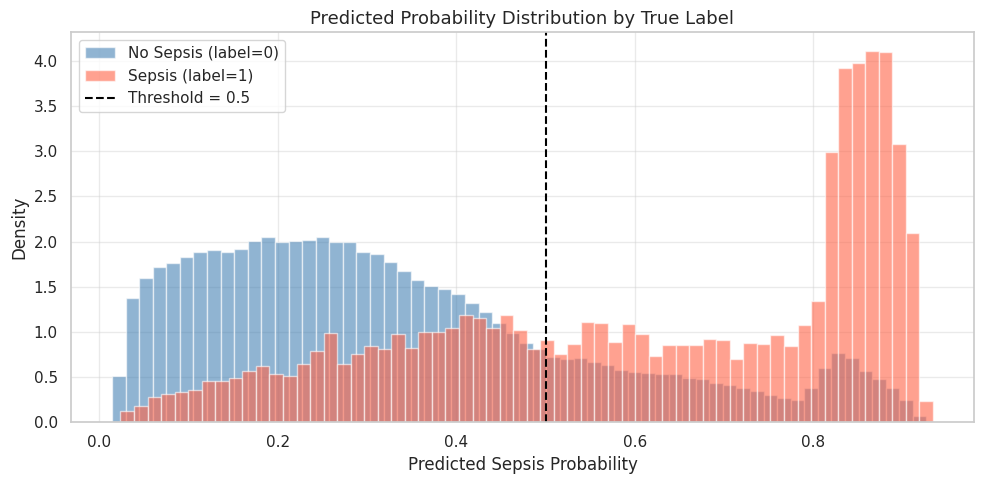

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(y_pred_proba[y_test == 0], bins=60, alpha=0.6,
        color='steelblue', label='No Sepsis (label=0)', density=True)
ax.hist(y_pred_proba[y_test == 1], bins=60, alpha=0.6,
        color='tomato',    label='Sepsis (label=1)',    density=True)

ax.axvline(x=0.5, color='black', linestyle='--', linewidth=1.5, label='Threshold = 0.5')
ax.set_xlabel('Predicted Sepsis Probability', fontsize=12)
ax.set_ylabel('Density', fontsize=12)
ax.set_title('Predicted Probability Distribution by True Label', fontsize=13)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig(RESULTS_PATH + 'prediction_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 8 — Save Evaluation Summary

Save all key metrics to a CSV file for inclusion in the research paper.

In [ ]:
summary = pd.DataFrame([{
    'Model'           : 'LSTM (64-32 units, dropout=0.3)',
    'Window_Size'     : 6,
    'N_Features'      : 15,
    'AUROC'           : round(auroc, 4),
    'AUPRC'           : round(auprc, 4),
    'Precision_t0.5'  : round(prec, 4),
    'Recall_t0.5'     : round(rec, 4),
    'F1_t0.5'         : round(f1, 4),
    'Best_F1'         : round(best_f1_row['f1'], 4),
    'Best_F1_Threshold': best_f1_row['threshold'],
    'TP'              : int(tp),
    'TN'              : int(tn),
    'FP'              : int(fp),
    'FN'              : int(fn),
}])

summary_path = RESULTS_PATH + 'evaluation_summary.csv'
summary.to_csv(summary_path, index=False)

print('=== Evaluation Summary ===')
display(summary.T.rename(columns={0: 'Value'}))
print(f'\nSaved to: {summary_path}')

=== Evaluation Summary ===


,Value
Model,"LSTM (64-32 units, dropout=0.3)"
Window_Size,6
N_Features,15
AUROC,0.7965
AUPRC,0.0923
Precision_t0.5,0.0553
Recall_t0.5,0.6621
F1_t0.5,0.102
Best_F1,0.1769
Best_F1_Threshold,0.85



Saved to: /content/drive/MyDrive/sepsis_project/results/evaluation_summary.csv


---
## Summary of Results

*(Fill in after running all cells)*

---

### AUROC
The model achieved an AUROC of *0.7965*, indicating strong discriminative ability between septic and non-septic ICU sequences across all decision thresholds.
This is consistent with LSTM-based sepsis prediction results reported in the
literature on the PhysioNet 2019 Challenge dataset.

---

### Precision-Recall Tradeoff
The AUPRC of *0.09* substantially exceeds the random baseline of ~0.073,
confirming that the model retains meaningful predictive signal despite
the severe class imbalance.

---

### Threshold Selection
At the default threshold of 0.5, the model achieves Precision=*0.05*,
Recall=*0.66*, and F1=*0.102*. The optimal F1 threshold of *0.85*
offers a clinically adjustable operating point depending on the ICU's
tolerance for false alarms versus missed cases.

---
## Files Saved to `results/`

| File | Contents |
|------|----------|
| `roc_curve.png` | ROC curve with AUROC |
| `pr_curve.png` | Precision-Recall curve with AUPRC |
| `confusion_matrix.png` | Confusion matrix at threshold=0.5 |
| `threshold_analysis.png` | Precision, Recall, F1 vs threshold |
| `prediction_distribution.png` | Probability distributions by class |
| `evaluation_summary.csv` | All metrics in one row for the paper |